# Part 4: Two models, two parallel worlds: your first uplift model

*Series: Who Will Stay Because of Us? Uplift Modelling and Causal Inference for Client Attrition*

Every client could live in one of two worlds: the one where an RM negotiates pricing, and the one where nobody calls. We only ever see one of them. The simplest uplift model builds **one model per world**, then compares them.

**In this notebook**

1. Train the T-learner ("two models"): one XGBoost churn model on treated clients, one on control clients.
2. Turn the two predictions into an uplift score, and check the direction of the subtraction.
3. Compare the predictions with the true uplift (possible only because the bank is synthetic).
4. See how many more clients the model saves than calling the riskiest first.
5. Compare with the S-learner ("single model").

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_series import SERIES_SEED, analysis_pool, generate_bank
from uplift_series import plotting as P
from uplift_series.modeling import SLearner, TLearner, split_pool

P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)

df = generate_bank(assignment="random", seed=SERIES_SEED)
pool = analysis_pool(df)
train, test = split_pool(pool, test_size=0.3, seed=0)
print(f"train: {len(train):,} clients ({train['treated'].sum()} treated)   "
      f"test: {len(test):,} clients ({test['treated'].sum()} treated)")

train: 3,500 clients (700 treated)   test: 1,500 clients (300 treated)


## 1. One model per world

- **Model 1** learns from the 700 treated training clients only. It answers: *if this client gets pricing, how likely are they to leave?*
- **Model 2** learns from the 2,800 control training clients only. It answers: *if nobody calls, how likely are they to leave?*

Both are ordinary XGBoost churn classifiers with the same features and settings. Using the same inputs matters: if the two models saw different information, the gap between them would partly reflect that, not pricing.

The settings are deliberately simple (shallow trees, see `modeling.DEFAULT_XGB_PARAMS`), because Model 1 learns from only 700 clients.

In [2]:
tlearner = TLearner().fit(train)

test["p_no_action"] = tlearner.predict_churn_no_action(test)    # Model 2
test["p_pricing"] = tlearner.predict_churn_with_pricing(test)   # Model 1
test["pred_uplift"] = test["p_no_action"] - test["p_pricing"]

test[["p_no_action", "p_pricing", "pred_uplift", "treated", "churned_6m"]].head()

,p_no_action,p_pricing,pred_uplift,treated,churned_6m
24988,0.132,0.014,0.118,0,0
1580,0.128,0.071,0.057,0,0
32877,0.395,0.041,0.355,1,0
30342,0.090,0.027,0.063,0,0
3393,0.148,0.016,0.132,1,0


Every test client now has an estimate for **both** worlds, including the one they did not live in.

## 2. Check the direction

Uplift is **no-action churn minus pricing churn**, so a positive score means pricing helps. Subtract the other way round and the ranking flips: the model would send RMs to the clients pricing hurts most. Two quick checks:

- the average predicted uplift should be positive and close to the simple treated-versus-control difference in the training data;
- the clients with the highest scores should look like the price-sensitive clients from Part 2 (paying above peers).

In [3]:
simple_gap = (train.loc[train["treated"] == 0, "churned_6m"].mean()
              - train.loc[train["treated"] == 1, "churned_6m"].mean())
print(f"Average predicted uplift on test:          {test['pred_uplift'].mean() * 100:5.1f} points")
print(f"Treated vs control gap in training data:   {simple_gap * 100:5.1f} points")

test["score_band"] = pd.qcut(test["pred_uplift"], 5, labels=["lowest 20%", "2", "3", "4", "highest 20%"])
test.groupby("score_band", observed=True)[["pricing_gap"]].mean()

Average predicted uplift on test:            9.1 points
Treated vs control gap in training data:     8.2 points


,pricing_gap
score_band,
lowest 20%,-0.012
2,0.013
3,0.069
4,0.087
highest 20%,0.093


Average pricing gap rises steadily from the lowest to the highest score band: the clients the model rates highest are the ones paying most above peers, exactly the price-sensitive persuadables from Part 2. The direction is right.

## 3. How close are the predictions to the truth?

In real life this check is impossible. Here we can compare each test client's predicted uplift with their true uplift.

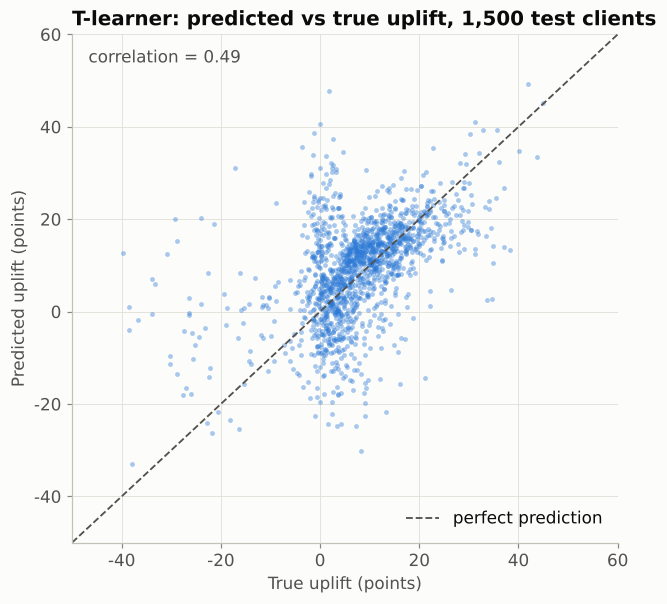

In [4]:
corr = np.corrcoef(test["pred_uplift"], test["true_uplift"])[0, 1]

fig, ax = plt.subplots(figsize=(6.4, 6))
ax.scatter(test["true_uplift"], test["pred_uplift"], s=10, color=P.BLUE, alpha=0.4, linewidths=0)
lims = [-0.5, 0.6]
ax.plot(lims, lims, color=P.INK_SECONDARY, linestyle="--", linewidth=1.2, label="perfect prediction")
ax.legend(loc="lower right")
ax.set_xlim(lims)
ax.set_ylim(lims)
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(lambda v, _: f"{v * 100:.0f}")
ax.set_xlabel("True uplift (points)")
ax.set_ylabel("Predicted uplift (points)")
ax.set_title("T-learner: predicted vs true uplift, 1,500 test clients")
ax.text(0.03, 0.97, f"correlation = {corr:.2f}", transform=ax.transAxes, va="top", color=P.INK_SECONDARY)
P.save(fig, "04_predicted_vs_true")
plt.show()

The predictions point the right way but are noisy: many clients get predicted uplifts well above or well below their true value. That is typical of the T-learner. Each of its two models makes its own errors, and subtracting two noisy numbers adds the noise together, especially for Model 1, which learns from only 700 clients.

For deciding **who to call**, what matters is the *ranking*, not the exact numbers. So the real test is targeting.

## 4. Does it pick better clients?

RMs can call 20% of the 1,500 test clients: 300 calls. Compare four ways to choose:

In [5]:
K = 300
rules = {
    "Random": test.sample(K, random_state=1),
    "Riskiest first": test.nlargest(K, "churn_score"),
    "T-learner": test.nlargest(K, "pred_uplift"),
    "Best possible (true uplift)": test.nlargest(K, "true_uplift"),
}
best = rules["Best possible (true uplift)"]["true_uplift"].sum()
targeting = pd.DataFrame({
    "expected clients saved": {k: v["true_uplift"].sum() for k, v in rules.items()},
    "share of best possible": {k: v["true_uplift"].sum() / best for k, v in rules.items()},
    "persuadables called": {k: (v["true_client_type"] == "persuadable").sum() for k, v in rules.items()},
    "lost causes called": {k: (v["true_client_type"] == "lost_cause").sum() for k, v in rules.items()},
    "sleeping dogs called": {k: (v["true_client_type"] == "sleeping_dog").sum() for k, v in rules.items()},
})
targeting

,expected clients saved,share of best possible,persuadables called,lost causes called,sleeping dogs called
Random,23.040,0.358,176,45,28
Riskiest first,11.477,0.178,74,176,44
T-learner,42.440,0.659,219,65,10
Best possible (true uplift),64.393,1.000,300,0,0


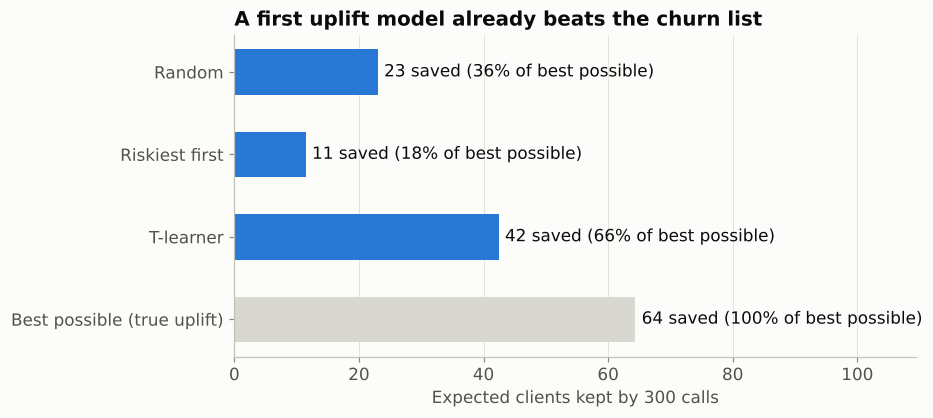

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
names = list(targeting.index)[::-1]
vals = targeting.loc[names, "expected clients saved"]
colors = [P.BACKGROUND_POINTS if n.startswith("Best") else P.BLUE for n in names]
bars = ax.barh(names, vals, color=colors, height=0.55)
for b, v, n in zip(bars, vals, names):
    share = targeting.loc[n, "share of best possible"]
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2,
            f"{v:.0f} saved ({share:.0%} of best possible)", va="center", color=P.INK, fontsize=11)
ax.set_xlim(0, vals.max() * 1.7)
ax.set_xlabel("Expected clients kept by 300 calls")
ax.grid(axis="y", visible=False)
ax.set_title("A first uplift model already beats the churn list")
P.save(fig, "04_targeting_payoff")
plt.show()

With nothing more than two standard churn models, the T-learner saves almost four times as many clients as calling the riskiest first, and captures a large share of what perfect knowledge of uplift would achieve.

### What a sign error costs

Here is the same model with the subtraction the wrong way round (pricing churn minus no-action churn), which is an easy slip in real code:

In [7]:
wrong = test.assign(wrong_sign=test["p_pricing"] - test["p_no_action"]).nlargest(K, "wrong_sign")
print(f"Expected clients saved with the sign flipped: {wrong['true_uplift'].sum():.1f}")
wrong["true_client_type"].value_counts()

Expected clients saved with the sign flipped: 0.7


true_client_type
sure_thing      99
persuadable     79
lost_cause      62
sleeping_dog    60
Name: count, dtype: int64

Flipping the sign fills the list with sure things, lost causes and sleeping dogs, and the 300 calls save almost nobody. Always confirm that positive uplift means "pricing helps" before ranking anything.

## 5. The S-learner: one model instead of two

The **S-learner** trains a single churn model on all clients, with the treatment flag as one more input. To score a client, it predicts twice, once with the flag set to "pricing" and once to "no action", and subtracts.

Its strength is that every client helps train the one model, instead of the treated model learning from only 700 clients. Its weakness: if the treatment flag looks unimportant to the trees, the model can largely ignore it, and the predicted uplifts shrink towards zero.

In [8]:
slearner = SLearner().fit(train)
test["pred_uplift_s"] = slearner.predict_uplift(test)

def summary(col):
    top = test.nlargest(K, col)["true_uplift"].sum()
    return {
        "correlation with truth": np.corrcoef(test[col], test["true_uplift"])[0, 1],
        "spread of predictions (sd, pts)": 100 * test[col].std(),
        "share of best possible (300 calls)": top / best,
    }

comparison = pd.DataFrame({"T-learner": summary("pred_uplift"), "S-learner": summary("pred_uplift_s")})
comparison.loc["spread of predictions (sd, pts)", "truth"] = 100 * test["true_uplift"].std()
comparison

,T-learner,S-learner,truth
correlation with truth,0.494,0.550,NaN
"spread of predictions (sd, pts)",10.949,3.061,10.360
share of best possible (300 calls),0.659,0.679,NaN


Both models rank clients usefully, and they err in opposite directions:

- the **T-learner** is noisy: its predictions spread about as widely as the true uplifts, but much of that spread is error;
- the **S-learner** shrinks: its predictions are squeezed towards zero, spreading far less than the true uplifts.

For choosing *who* to call, the ranking is what counts. For turning uplift into *money* (Part 7), the size of each estimate matters too, and both biases will need attention. This series continues with the T-learner because it is the easiest to explain ("one model per world") and because it maps directly onto the propensity weighting in Act 3. More advanced learners, such as the X-learner and causal forests, are covered briefly in Part 10.

## Takeaways

- The **T-learner** trains one churn model on treated clients and one on control clients. Uplift = no-action churn minus pricing churn.
- Use the **same features** in both models, and **check the sign**: a flipped subtraction sends RMs to the clients pricing hurts most.
- Predicted uplift is noisy for individual clients, but the **ranking** already saves far more clients than the churn list.
- The **S-learner** pools all clients into one model; it ranks about as well here, but shrinks the size of every estimate.

**Next, Part 5:** in this notebook we cheated by checking against the true uplift. A real bank cannot. How do you grade a prediction that can never be checked for a single client?